# Удовлетворённость авиапассажиров: модель и абляции

В ДЗ 2 продолжаем [исследование baseline](01_satisfaction_research.ipynb). Сравним логистическую регрессию с LightGBM и проверим, помогают ли модели два произведения оценок услуг. Используем конкурсный `train.csv` и метрику ROC-AUC. Данные синтетические, поэтому по ним нельзя судить о переносе результата на реальных пассажиров.

## Вопросы и протокол

Проверим две идеи: повысит ли LightGBM качество на исходных признаках и помогут ли ему дополнительные сочетания оценок услуг.

В ДЗ 1 логистическая регрессия допускала уверенные ошибки. Её общий OOF ROC-AUC составил 0,651831 на личных поездках и 0,919792 на деловых. LightGBM может описывать пороги и сочетания признаков, поэтому сравним его с линейной моделью. Срез сам по себе не объясняет ошибки и не доказывает, что они связаны с линейностью baseline.

Для новых признаков выбраны две пары. Признак A равен произведению оценок Wi-Fi и онлайн-посадки и может помочь модели учесть сочетание цифровых сервисов. Признак B равен произведению оценок кресла и развлечений и может помочь учесть сочетание услуг во время полёта. Выбор опирается на прежнюю работу с этими данными и публикации, указанные в [протоколе](../reports/hw2/protocol.md). Деревья способны находить взаимодействия и без новых столбцов, поэтому прирост заранее не гарантирован.

Сравним пять вариантов:

| Опыт | Модель | Дополнительные признаки |
|---|---|---|
| E0 | Логистическая регрессия из ДЗ 1 | Нет |
| E1 | LightGBM | Нет |
| E2 | LightGBM | A |
| E3 | LightGBM | B |
| E4 | LightGBM | A и B |

Во всех опытах используем одни и те же пять стратифицированных фолдов, seed 42 и одинаковую предобработку исходных признаков. Значения для заполнения пропусков, масштабирование и one-hot-кодирование определяются только по обучающей части фолда. Новые признаки рассчитываются построчно, без целевой переменной. Нули в оценках сохраняем как числа: их смысл неизвестен.

Сравнение E1 − E0 показывает разницу между моделями на исходных признаках. E4 − E1 показывает изменение после добавления обоих признаков к LightGBM. Для абляций сравним E4 − E3, то есть добавление A при наличии B, и E4 − E2, добавление B при наличии A. Эти эффекты не обязаны складываться.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

root = Path.cwd()
if not (root / "configs/hw2.yaml").exists():
    root = root.parent
assert (root / "configs/hw2.yaml").exists(), "Запустите ноутбук из корня проекта или каталога notebooks"
report = root / "reports/hw2"
summary = pd.read_csv(report / "summary.csv")
folds = pd.read_csv(report / "folds.csv")
comparisons = pd.read_csv(report / "comparisons.csv")
slices = pd.read_csv(report / "slices.csv")

## Воспроизведение

Ноутбук показывает результаты исходного запуска, сохранённые в `reports/hw2/`. Его численные выводы относятся к этим таблицам.

Чтобы повторить серию, выполните из корня проекта `./scripts/run_hw2.sh`, затем `python -m src.verify_hw2`, `python -m src.compare_hw2` и `python scripts/build_hw2_report.py`. Первая проверка сверяет файлы нового запуска между собой, вторая сравнивает метрики по фолдам с опубликованными. Новый отчёт появится в `outputs/hw2/report/`; сохранённые результаты при этом не изменятся. Для каждого повтора нужен пустой выходной каталог. Подробнее установка и запуск описаны в [README](../README.md).

## Качество моделей

Основная метрика в исследовании: средний ROC-AUC по пяти фолдам. В таблице также приведены стандартное отклонение по фолдам, ROC-AUC по объединённым OOF-прогнозам, средний average precision (AP, сводная метрика precision–recall) и общее время обучения на пяти фолдах. Общий OOF ROC-AUC может отличаться от среднего: при его расчёте сравниваются и оценки, полученные на разных фолдах. Время включает подгонку предобработки и обучение модели; оно зависит от компьютера.

In [2]:
table = summary[["experiment", "model", "features", "mean_fold_auc", "std_fold_auc", "pooled_oof_auc", "mean_fold_ap", "fit_seconds_total"]].copy()
table = table.rename(columns={"experiment": "Опыт", "model": "Модель", "features": "Признаки", "mean_fold_auc": "ROC-AUC: среднее", "std_fold_auc": "ROC-AUC: SD", "pooled_oof_auc": "ROC-AUC: общий OOF", "mean_fold_ap": "AP: среднее", "fit_seconds_total": "Обучение, с"})
table["Модель"] = table["Модель"].replace({"logistic": "Логистическая регрессия", "lightgbm": "LightGBM"})
display(table.round(6).set_index("Опыт"))

,Модель,Признаки,ROC-AUC: среднее,ROC-AUC: SD,ROC-AUC: общий OOF,AP: среднее,"Обучение, с"
Опыт,,,,,,,
E0,Логистическая регрессия,нет,0.921555,0.000436,0.921556,0.908974,12.015
E1,LightGBM,нет,0.958039,0.000668,0.958028,0.941970,82.376
E2,LightGBM,A,0.958028,0.000679,0.958015,0.941953,85.860
E3,LightGBM,B,0.958076,0.000626,0.958063,0.941925,87.942
E4,LightGBM,A+B,0.958059,0.000643,0.958049,0.941876,88.018


На исходных признаках LightGBM достигает среднего ROC-AUC **0,958039**, а логистическая регрессия достигает **0,921555**. Разница положительна на всех пяти фолдах. Вместе с моделью меняется несколько её свойств, поэтому приписать улучшение одной нелинейности нельзя.

Максимальное среднее в этой серии показал E3: **0,958076**. Вариант выбран по тем же данным, на которых оценивался, поэтому его преимущество перед другими конфигурациями не подтверждено независимой проверкой.

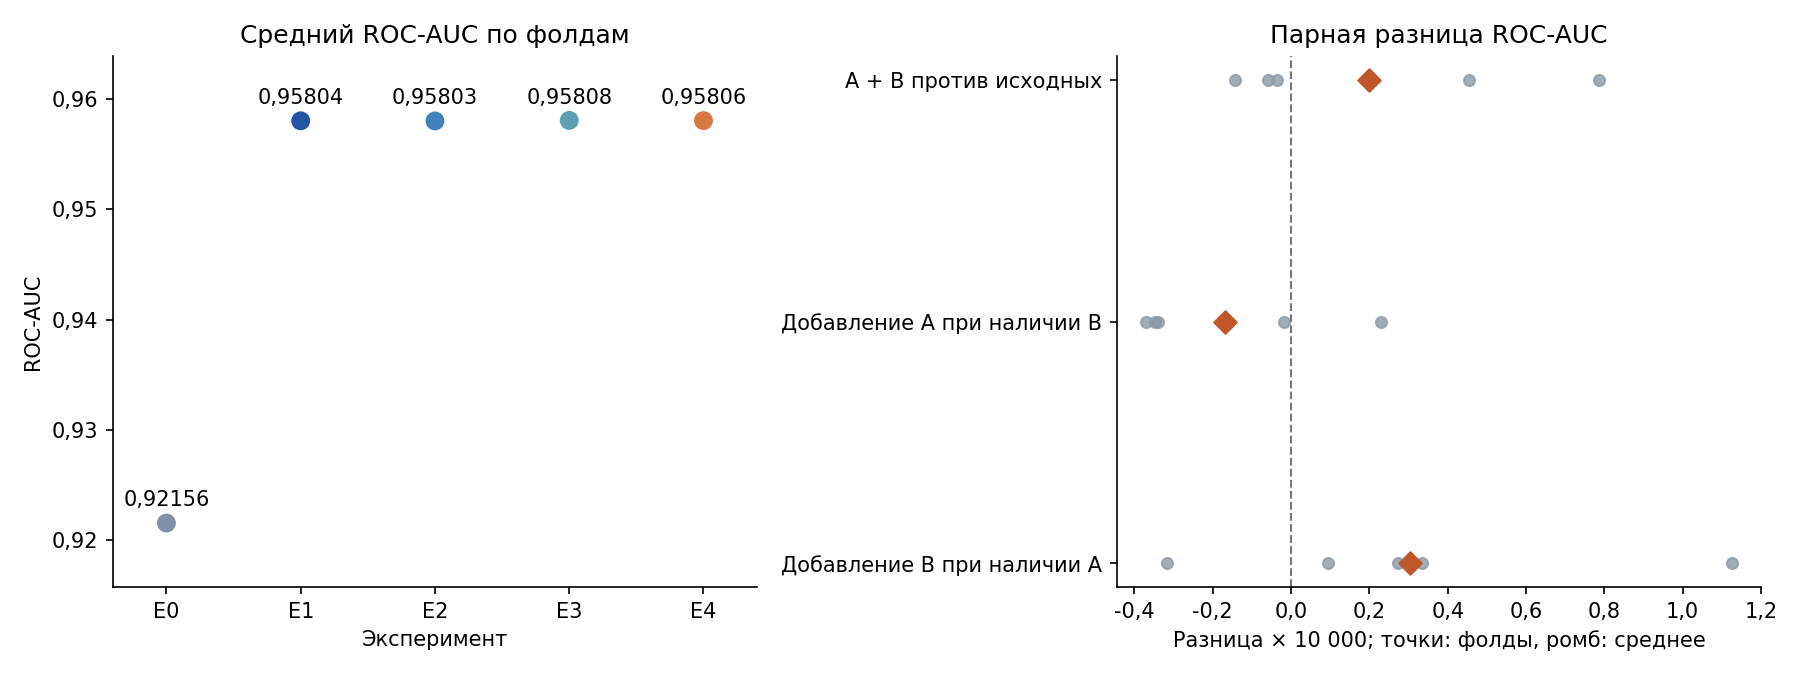

In [3]:
display(Image(filename=str(report / "comparison.png")))

На правом графике каждая точка показывает разницу ROC-AUC двух вариантов на одном фолде. Ромб показывает среднюю разницу. Для удобства значения умножены на 10 000. Обучающие части фолдов пересекаются, поэтому разброс точек служит описательной оценкой и не заменяет проверку на независимых наборах данных.

## Абляции

В каждом из двух сравнений из полной конфигурации E4 убран один признак. Разница равна ROC-AUC первого варианта минус ROC-AUC второго на тех же строках. Положительное значение означает преимущество первого варианта. В таблицах среднюю и фолдовые разницы умножаем на 10 000. Стандартное отклонение описывает разброс пяти разниц; доверительным интервалом оно не является.

In [4]:
labels = {"model": "Модель: E1 − E0", "both_features": "A и B: E4 − E1", "ablate_A": "A при B: E4 − E3", "ablate_B": "B при A: E4 − E2"}
columns = ["mean_auc_delta", "std_auc_delta", "positive_folds"]
comparison_table = comparisons.set_index("comparison")[columns].copy()
comparison_table[["mean_auc_delta", "std_auc_delta"]] *= 10_000
comparison_table = comparison_table.rename(index=labels, columns={"mean_auc_delta": "Средняя разница × 10 000", "std_auc_delta": "SD × 10 000", "positive_folds": "Фолдов с разницей > 0"})
comparison_table.index.name = "Сравнение"
display(comparison_table.round(3))
fold_columns = [f"fold_{i}_delta" for i in range(1, 6)]
fold_deltas = comparisons.set_index("comparison")[fold_columns].rename(index=labels).T * 10_000
fold_deltas.index = [f"Фолд {i}" for i in range(1, 6)]
fold_deltas.index.name = "Разница × 10 000"
fold_deltas.columns.name = "Сравнение"
display(fold_deltas.round(3))

,Средняя разница × 10 000,SD × 10 000,Фолдов с разницей > 0
Сравнение,,,
Модель: E1 − E0,364.834,8.269,5
A и B: E4 − E1,0.200,0.360,2
A при B: E4 − E3,-0.169,0.238,1
B при A: E4 − E2,0.302,0.470,4


Сравнение,Модель: E1 − E0,A и B: E4 − E1,A при B: E4 − E3,B при A: E4 − E2
Разница × 10 000,,,,
Фолд 1,355.933,-0.037,-0.370,0.335
Фолд 2,353.831,0.785,-0.347,1.126
Фолд 3,373.573,-0.060,0.229,0.272
Фолд 4,369.211,-0.143,-0.340,-0.317
Фолд 5,371.621,0.454,-0.017,0.095


При добавлении A и B к E1 средний ROC-AUC вырос на **0,000020**, но разница положительна лишь в двух фолдах из пяти. Добавление A к модели с B дало в среднем **−0,000017** и положительную разницу в одном фолде. Добавление B к модели с A дало **+0,000030** в среднем и положительную разницу в четырёх фолдах.

Эффекты намного меньше разницы между моделями, а их знак меняется от фолда к фолду. Поэтому по этой серии нельзя уверенно заключить, что признаки устойчиво улучшают качество. Возможно, деревья уже находят сочетания исходных оценок без новых признаков. Кроме того, одинаковое произведение может получиться из разных пар оценок. Эксперимент не позволяет установить причину малого эффекта.

## Срез по типу поездки

Сравним ROC-AUC по объединённым OOF-прогнозам для логистической регрессии и двух вариантов LightGBM. На графике указаны размеры групп и доли положительных ответов. Точки показывают значения метрики; интервалы неопределённости здесь не рассчитаны. Это описательное сравнение на тех же данных, а не проверка на отдельной выборке.

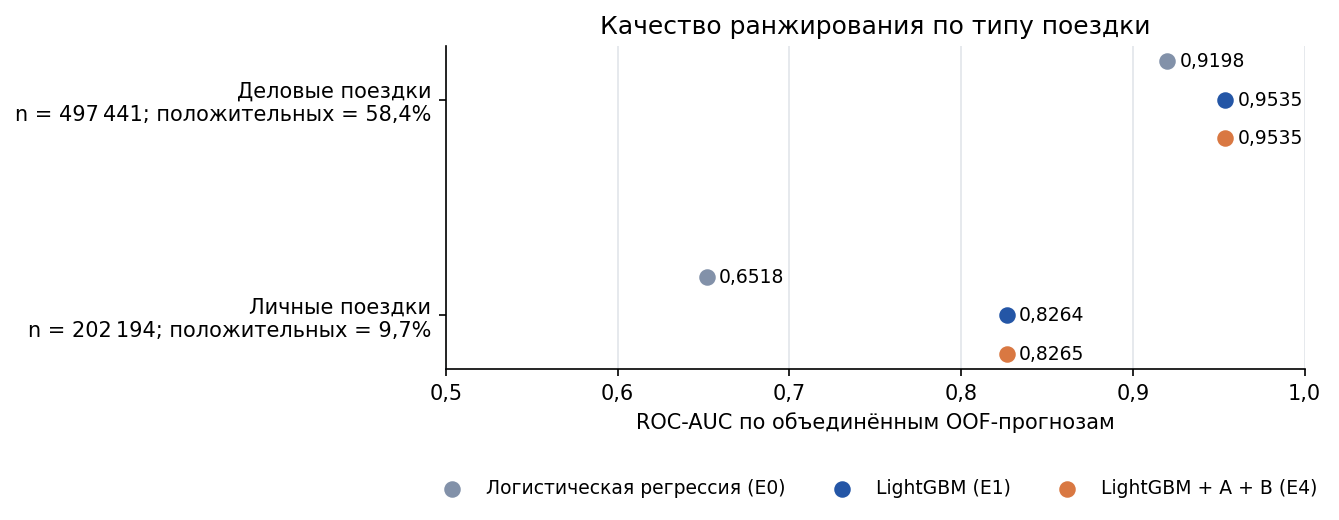

In [5]:
display(Image(filename=str(report / "travel_slices.png")))

На личных поездках ROC-AUC вырос с **0,651831** у E0 до **0,826383** у E1. Для деловых поездок ROC-AUC модели E1 выше и составляет **0,953475**. У E4 разница между группами также сохраняется. Эти показатели не характеризуют ошибки при конкретном пороге и не подтверждают полезность модели для авиакомпании. Калибровку и перенос на другие данные мы не проверяли.

## Ограничения и выводы

На выбранных фолдах LightGBM ранжировал пассажиров лучше baseline. Два дополнительных признака дали малые и неоднородные изменения, поэтому их практическая польза остаётся открытым вопросом. Поскольку данные уже использовались в конкурсной работе, эта серия не является независимым подтверждением выбранных идей.

Доверительный интервал из ДЗ 1 относится к общему OOF ROC-AUC baseline при фиксированных прогнозах. Он не оценивает разницу между моделями. При расчёте интервала модели повторно не обучались, поэтому интервал не учитывает разброс обучения.

Дальше можно повторить фиксированные сравнения на других разбиениях и изучить срезы. Такие разбиения не станут независимыми наборами данных. Ещё один вопрос: как изменится качество без оценок услуг, если в предполагаемом сценарии они недоступны. Для проверки переноса потребуются новые данные и сведения о том, когда появляются признаки.